# 02 · Leptospirosis cases

**Goal:** understand the target on its own. Where are the cases, how do they move over time,
and what does their distribution mean for the model?

In [1]:
from common import *

style()
d = lepto_weekly()
d["year"] = d.date.dt.year
d["woy"] = d.date.dt.isocalendar().week.astype(int).clip(upper=52)

## 1. Which cities carry the burden?

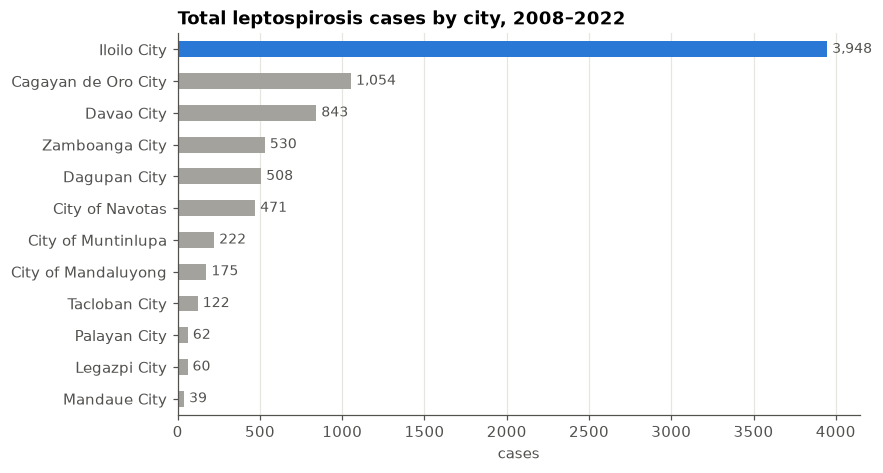

Iloilo: 3,948 of 8,034 cases (49%)


In [2]:
by_city = d.groupby("city").cases.sum().sort_values()
ax = by_city.plot.barh(color=[BLUE if c == ILOILO else GREY for c in by_city.index], figsize=(8, 4.5))
ax.set(title="Total leptospirosis cases by city, 2008–2022", xlabel="cases", ylabel="")
ax.grid(axis="y", visible=False)
for i, v in enumerate(by_city):
    ax.text(v + 30, i, f"{v:,}", va="center", color=MUTED, fontsize=9)
plt.show()
print(f"Iloilo: {by_city[ILOILO]:,} of {by_city.sum():,} cases ({by_city[ILOILO] / by_city.sum():.0%})")

**Takeaway:** Iloilo City alone has about half of all cases across the 12 cities. That's why it's
the target city. Most other cities average well under one case a week.

## 2. Over time

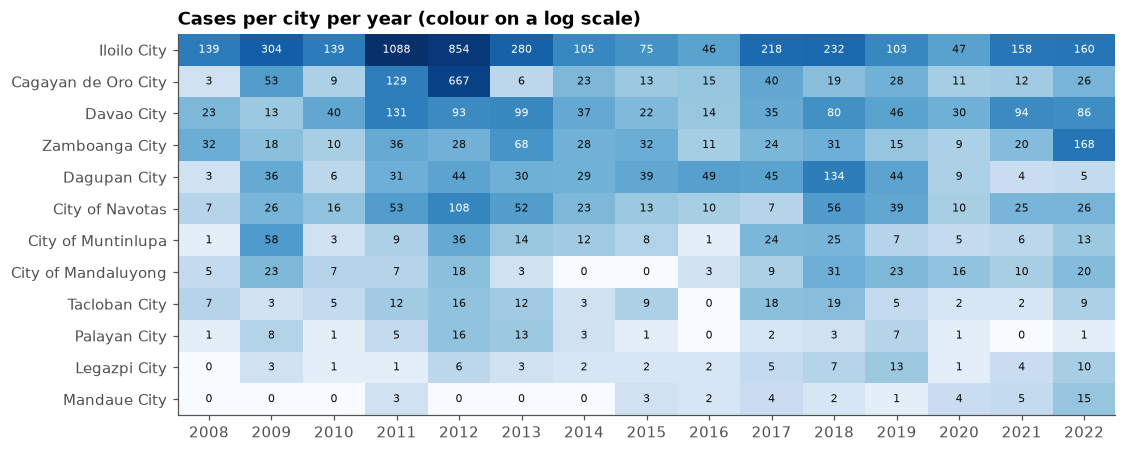

In [3]:
yearly = d.pivot_table(index="city", columns="year", values="cases", aggfunc="sum")
yearly = yearly.loc[by_city.index[::-1]]
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(np.log1p(yearly), cmap="Blues", aspect="auto")
ax.set_xticks(range(yearly.shape[1]), yearly.columns)
ax.set_yticks(range(yearly.shape[0]), yearly.index)
ax.grid(False)
for (i, j), v in np.ndenumerate(yearly.values):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=7.5,
            color="white" if np.log1p(v) > np.log1p(yearly.values).max() * 0.6 else INK)
ax.set_title("Cases per city per year (colour on a log scale)")
plt.show()

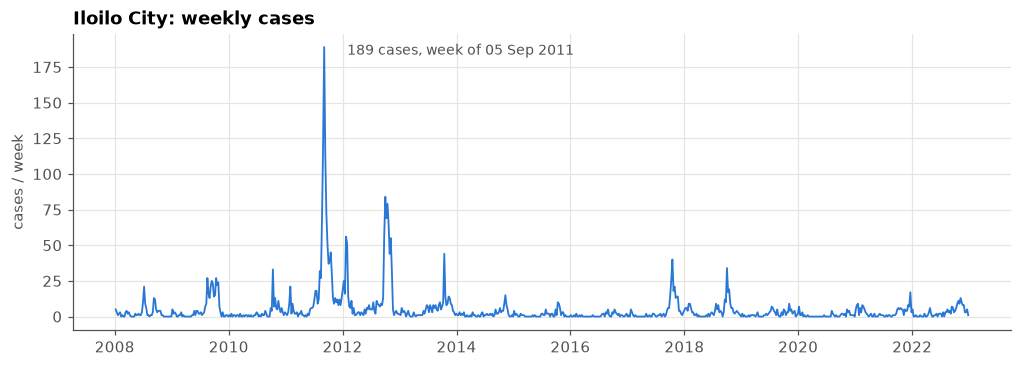

In [4]:
il = d[d.city == ILOILO]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(il.date, il.cases, color=BLUE, linewidth=1.2)
ax.set(title="Iloilo City: weekly cases", ylabel="cases / week")
peak = il.loc[il.cases.idxmax()]
ax.annotate(f"{peak.cases} cases, week of {peak.date:%d %b %Y}", (peak.date, peak.cases),
            xytext=(15, -5), textcoords="offset points", color=MUTED, fontsize=9)
plt.show()

**Takeaways**
- **2011–2012 were outbreak years.** Iloilo had 1,088 and 854 cases (typical year: 100–250), and
  Cagayan de Oro had 667 in 2012, around Typhoon Sendong (Washi, Dec 2011).
- Cases come in **sharp spikes**: Iloilo's worst week (Sep 2011) had 189 cases. Any model must
  cope with rare, very large weeks, and the robustness checks should test results with and
  without these years.
- Zamboanga's jump to 168 in 2022 is another isolated outbreak.

## 3. Seasonality

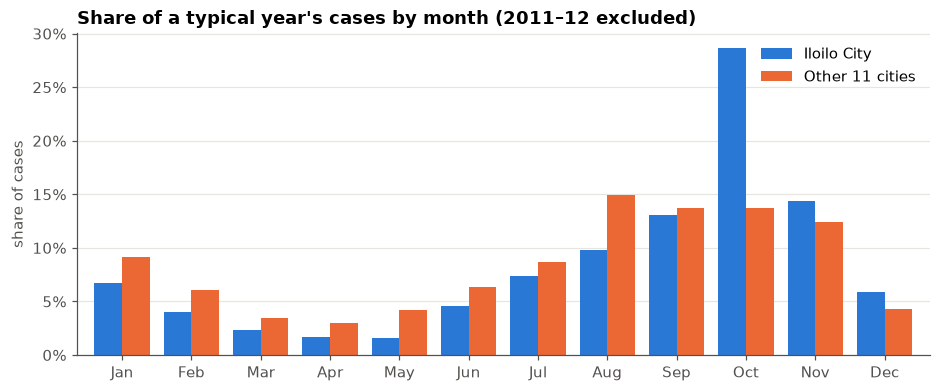

In [5]:
# Outbreak years excluded so one storm doesn't define the "typical" year.
typical = d[~d.year.isin([2011, 2012])]
grp = np.where(typical.city == ILOILO, ILOILO, "Other 11 cities")
month = typical.groupby([grp, typical.date.dt.month]).cases.sum().unstack(0)
share = month / month.sum()
ax = share.plot.bar(color=[BLUE, ORANGE], width=0.8, figsize=(10, 3.8))
ax.set_xticklabels(pd.date_range("2000-01", periods=12, freq="MS").strftime("%b"), rotation=0)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set(title="Share of a typical year's cases by month (2011–12 excluded)", xlabel="", ylabel="share of cases")
ax.grid(axis="x", visible=False)
ax.legend()
plt.show()

**Takeaway:** cases peak in the **wet season, August–November**. Iloilo peaks hard in
**October** (~29% of a typical year's cases). The seasonal shape is
shared across cities, so the model needs a seasonal term. Otherwise "it rained" and "it's
September" get confused.

## 4. Distribution: many zeros, rare large counts

In [6]:
stats = d.groupby("city").cases.agg(
    mean="mean", variance="var", zero_weeks=lambda s: (s == 0).mean(), max="max"
).sort_values("mean", ascending=False)
stats["var/mean"] = stats.variance / stats["mean"]
stats.style.format({"mean": "{:.2f}", "variance": "{:.1f}", "zero_weeks": "{:.0%}", "var/mean": "{:.0f}"})

,mean,variance,zero_weeks,max,var/mean
city,,,,,
Iloilo City,5.06,165.2,28%,189,33
Cagayan de Oro City,1.35,420.8,78%,554,311
Davao City,1.08,6.0,51%,39,6
Zamboanga City,0.68,16.0,67%,107,23
Dagupan City,0.65,3.7,75%,21,6
City of Navotas,0.60,6.1,75%,52,10
City of Muntinlupa,0.28,2.3,87%,32,8
City of Mandaluyong,0.22,0.6,86%,10,3
Tacloban City,0.16,0.3,89%,7,2


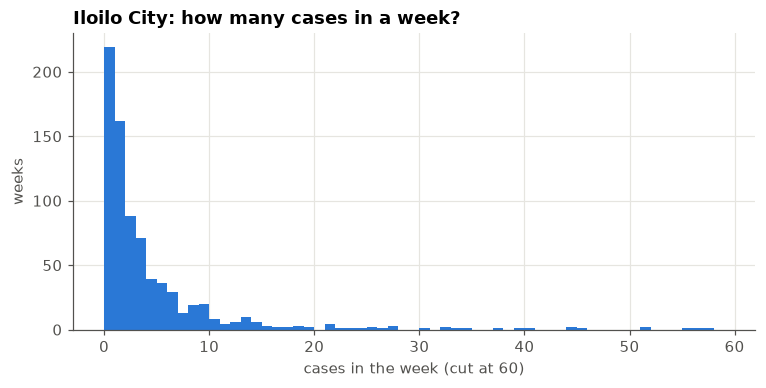

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(il.cases, bins=range(0, 60), color=BLUE)
ax.set(title="Iloilo City: how many cases in a week?", xlabel="cases in the week (cut at 60)", ylabel="weeks")
plt.show()

**Takeaways**
- Most city-weeks are **zero** (28% in Iloilo, over 75% in most cities).
- Variance is far above the mean (Iloilo: 33×), so the counts are **overdispersed**.
  A Poisson model would be overconfident. A **negative binomial** model fits this shape.

## Summary

| Finding | Implication |
|---|---|
| Iloilo has ~half of all cases | Target city; pool all 12 cities to learn the rain effect |
| 2011–12 outbreaks (Sendong era) | Test results with and without them |
| Wet-season peak (Jul–Oct) | Control for season so rain isn't just a proxy for the calendar |
| Mostly zeros, overdispersed | Negative binomial count model |